# City Events Exploration

Goal: pull major Chicago sports schedules + venue locations, sanity-check the data, and look for visible Divvy demand spikes near venues on game days.

**Scope (MVP):**
1. Cubs home games at Wrigley — densest Divvy stations
2. Hardcoded venue table for Soldier Field, United Center, Guaranteed Rate Field
3. Visual: games per month / weekday distribution
4. Validate signal: ride counts at stations near Wrigley on game vs non-game days

Install: `uv add pybaseball` (or `pip install pybaseball`) for Cubs schedules.

## 1. Setup

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from dotenv import load_dotenv
from divvy_demand.infra.s3_client import S3Client

load_dotenv('../../.env')
s3 = S3Client(env='prod')

## 2. Venue table

Hardcoded — these don't move. Lat/lng pulled from public records.

In [8]:
venues = pd.DataFrame([
    {'venue': 'Wrigley Field',           'team': 'Cubs',       'sport': 'MLB', 'lat': 41.9484, 'lng': -87.6553, 'capacity': 41649},
    {'venue': 'Guaranteed Rate Field',   'team': 'White Sox',  'sport': 'MLB', 'lat': 41.8299, 'lng': -87.6338, 'capacity': 40615},
    {'venue': 'United Center',           'team': 'Bulls/Hawks','sport': 'NBA/NHL', 'lat': 41.8807, 'lng': -87.6742, 'capacity': 23500},
    {'venue': 'Soldier Field',           'team': 'Bears/Fire', 'sport': 'NFL/MLS', 'lat': 41.8623, 'lng': -87.6167, 'capacity': 61500},
    {'venue': 'Wintrust Arena',          'team': 'Sky',        'sport': 'WNBA', 'lat': 41.8538, 'lng': -87.6256, 'capacity': 10387},
])
venues

,venue,team,sport,lat,lng,capacity
0,Wrigley Field,Cubs,MLB,41.9484,-87.6553,41649
1,Guaranteed Rate Field,White Sox,MLB,41.8299,-87.6338,40615
2,United Center,Bulls/Hawks,NBA/NHL,41.8807,-87.6742,23500
3,Soldier Field,Bears/Fire,NFL/MLS,41.8623,-87.6167,61500
4,Wintrust Arena,Sky,WNBA,41.8538,-87.6256,10387


## 3. Cubs home games

MLB: 81 home games per season, mostly Apr–Sep. `pybaseball.schedule_and_record` returns the full schedule for a team-season.

In [9]:
from pybaseball import schedule_and_record

# Monkey-patch pybaseball's broken make_numeric (fails on 'Unknown' attendance under CoW + Arrow strings)
import pybaseball.team_results as _tr
def _make_numeric_safe(data):
    for col in ['R', 'RA', 'Inn', 'Rank', 'Attendance']:
        data[col] = pd.to_numeric(data[col], errors='coerce')
    return data
_tr.make_numeric = _make_numeric_safe

SEASONS = list(range(2021, 2026))
frames = []
for yr in SEASONS:
    sched = schedule_and_record(yr, 'CHC')
    sched = sched[sched['Home_Away'] == 'Home'].copy()
    sched['season'] = yr
    frames.append(sched)
cubs = pd.concat(frames, ignore_index=True)

# Parse the Date column — pybaseball returns strings like 'Thursday, Mar 30'
cubs['date'] = pd.to_datetime(
    cubs['Date'].str.replace(r' \(\d+\)', '', regex=True) + ' ' + cubs['season'].astype(str),
    format='%A, %b %d %Y',
    errors='coerce',
)
cubs = cubs.dropna(subset=['date'])
cubs = cubs[['season', 'date', 'Opp', 'D/N', 'W/L', 'Attendance']].rename(
    columns={'Opp': 'opponent', 'D/N': 'day_night', 'W/L': 'result', 'Attendance': 'attendance'}
)
print(f'Cubs home games: {len(cubs):,}  ({cubs["date"].min().date()} → {cubs["date"].max().date()})')
cubs.head()

In [16]:
# Sanity: games per season (should be ~81, fewer for 2020 if included)
cubs.groupby('season').size().to_frame('home_games')

,home_games
season,
2021,81
2022,81
2023,81
2024,80
2025,80


## 4. Temporal pattern of game days

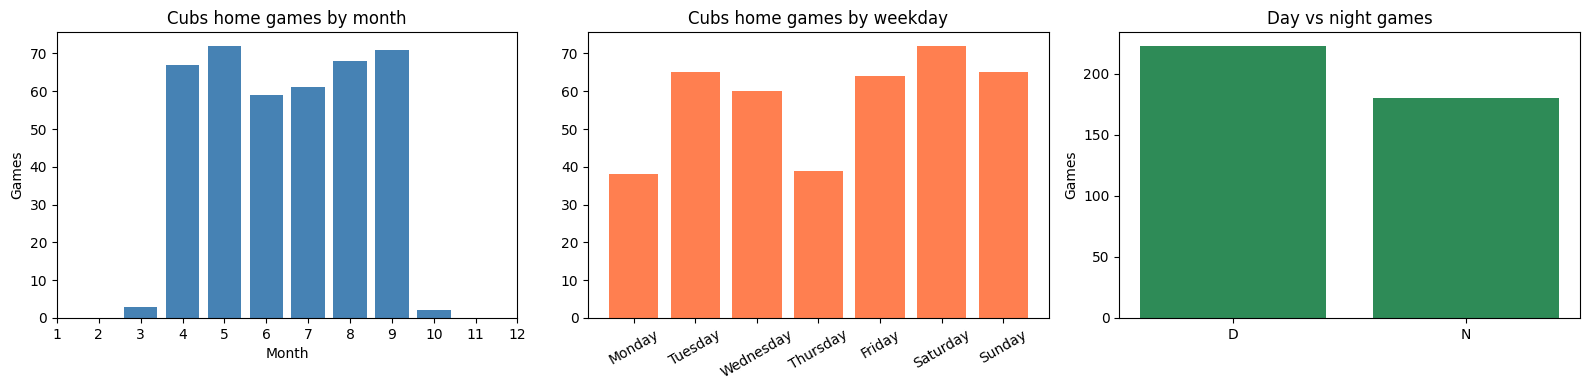

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Games per month
by_month = cubs.assign(month=cubs['date'].dt.month).groupby('month').size()
axes[0].bar(by_month.index, by_month.values, color='steelblue')
axes[0].set_title('Cubs home games by month')
axes[0].set_xlabel('Month'); axes[0].set_ylabel('Games')
axes[0].set_xticks(range(1, 13))

# Games per weekday
by_dow = cubs.assign(dow=cubs['date'].dt.day_name()).groupby('dow').size().reindex(
    ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
)
axes[1].bar(by_dow.index, by_dow.values, color='coral')
axes[1].set_title('Cubs home games by weekday')
axes[1].tick_params(axis='x', rotation=30)

# Day vs night
by_dn = cubs['day_night'].value_counts()
axes[2].bar(by_dn.index, by_dn.values, color='seagreen')
axes[2].set_title('Day vs night games')
axes[2].set_ylabel('Games')

plt.tight_layout()
plt.show()

## 5. Signal check: rides near Wrigley on game vs non-game days

If event-day demand spikes are real, we should see a clear lift at stations within ~1 km of Wrigley on Cubs home game days vs other days in the same season.

In [18]:
station = s3.read_processed('station')
station['date'] = pd.to_datetime(station['date'])
station = station[station['start_station_name'] != 'Outside of Dock']

# Get station coords from raw trip data
raw_frames = []
for month in [3, 6, 9]:
    raw = s3.read_raw(2024, month)
    raw_frames.append(raw[['start_station_name', 'start_lat', 'start_lng']].dropna())
station_coords = (
    pd.concat(raw_frames, ignore_index=True)
    .groupby('start_station_name')[['start_lat', 'start_lng']]
    .mean().reset_index()
)
print(f'Stations with coords: {len(station_coords):,}')

Stations with coords: 1,600


In [19]:
def haversine_km(lat1, lng1, lat2, lng2):
    R = 6371.0
    lat1, lng1, lat2, lng2 = map(np.radians, [lat1, lng1, lat2, lng2])
    dlat, dlng = lat2 - lat1, lng2 - lng1
    a = np.sin(dlat/2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlng/2)**2
    return 2 * R * np.arcsin(np.sqrt(a))

wrigley = venues.loc[venues['venue'] == 'Wrigley Field'].iloc[0]
station_coords['dist_wrigley_km'] = haversine_km(
    station_coords['start_lat'], station_coords['start_lng'],
    wrigley['lat'], wrigley['lng'],
)
near_wrigley = station_coords[station_coords['dist_wrigley_km'] <= 1.0]
print(f'Stations within 1 km of Wrigley: {len(near_wrigley)}')
near_wrigley.sort_values('dist_wrigley_km').head(10)

Stations within 1 km of Wrigley: 20


,start_station_name,start_lat,start_lng,dist_wrigley_km
1384,Sheffield Ave & Waveland Ave,41.949346,-87.654500,0.124287
1597,Wrigley Events Parking Area,41.947199,-87.653952,0.173984
1522,Weekend Night Parking Area A,41.946296,-87.655694,0.236212
1523,Weekend Night Parking Area B,41.944909,-87.654769,0.390685
181,Clark St & Grace St,41.950803,-87.659181,0.417673
189,Clark St & Newport St,41.944508,-87.654717,0.435438
78,Broadway & Waveland Ave,41.949066,-87.648624,0.557022
1524,Weekend Night Parking Area C,41.944793,-87.649479,0.626571
1393,Sheridan Rd & Irving Park Rd,41.954235,-87.654435,0.652739
76,Broadway & Sheridan Rd,41.952814,-87.650003,0.657889


In [20]:
# Aggregate daily rides at near-Wrigley stations
near_set = set(near_wrigley['start_station_name'])
near_rides = (
    station[station['start_station_name'].isin(near_set)]
    .groupby('date')['total_rides'].sum().rename('rides_near_wrigley').reset_index()
)

# Mark game days
near_rides['is_game_day'] = near_rides['date'].isin(set(cubs['date']))
near_rides['month']       = near_rides['date'].dt.month
near_rides['dow']         = near_rides['date'].dt.weekday

# Restrict to in-season months (Apr–Sep) for fair comparison
in_season = near_rides[near_rides['month'].between(4, 9)]

summary = in_season.groupby('is_game_day')['rides_near_wrigley'].agg(['mean', 'median', 'count'])
print('Daily rides near Wrigley (Apr–Sep):')
print(summary)

lift = summary.loc[True, 'mean'] / summary.loc[False, 'mean'] - 1
print(f'\nGame-day mean lift: {lift:.1%}')

Daily rides near Wrigley (Apr–Sep):
                    mean  median  count
is_game_day                            
False         880.706629   893.0    709
True         1087.496124  1096.0    387

Game-day mean lift: 23.5%


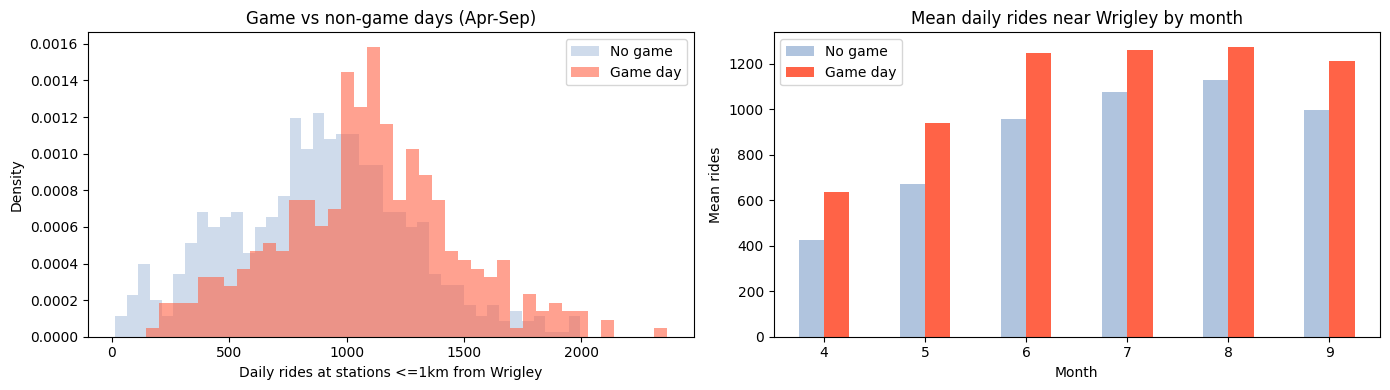

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Distribution overlay
for is_game, color, label in [(False, 'lightsteelblue', 'No game'), (True, 'tomato', 'Game day')]:
    subset = in_season[in_season['is_game_day'] == is_game]['rides_near_wrigley']
    axes[0].hist(subset, bins=40, alpha=0.6, color=color, label=label, density=True)
axes[0].set_xlabel('Daily rides at stations <=1km from Wrigley')
axes[0].set_ylabel('Density')
axes[0].set_title('Game vs non-game days (Apr-Sep)')
axes[0].legend()

# Lift by month
monthly = in_season.groupby(['month', 'is_game_day'])['rides_near_wrigley'].mean().unstack()
monthly.plot(kind='bar', ax=axes[1], color=['lightsteelblue', 'tomato'])
axes[1].set_title('Mean daily rides near Wrigley by month')
axes[1].set_xlabel('Month'); axes[1].set_ylabel('Mean rides')
axes[1].legend(['No game', 'Game day'])
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

## 6. Bears home games at Soldier Field

NFL: ~8–9 regular-season home games + occasional preseason/playoffs. Mostly Sundays, Sep–Jan.

Using `nfl_data_py.import_schedules` — install with `uv add nfl-data-py`.

In [21]:
import nfl_data_py as nfl

SEASONS = list(range(2021, 2026))
sched = nfl.import_schedules(SEASONS)
bears = sched[sched['home_team'] == 'CHI'].copy()
bears['date'] = pd.to_datetime(bears['gameday'])
bears = bears[['season', 'date', 'weekday', 'gametime', 'away_team', 'game_type', 'stadium']].rename(
    columns={'away_team': 'opponent'}
)
print(f'Bears home games: {len(bears):,}  ({bears["date"].min().date()} → {bears["date"].max().date()})')
bears.head()

Bears home games: 44  (2021-09-19 → 2026-01-18)


,season,date,weekday,gametime,opponent,game_type,stadium
5870,2021,2021-09-19,Sunday,13:00,CIN,REG,Soldier Field
5903,2021,2021-10-03,Sunday,13:00,DET,REG,Soldier Field
5936,2021,2021-10-17,Sunday,13:00,GB,REG,Soldier Field
5962,2021,2021-10-31,Sunday,13:00,SF,REG,Soldier Field
6005,2021,2021-11-21,Sunday,13:00,BAL,REG,Soldier Field


In [22]:
# Sanity: games per season
bears.groupby('season').size().to_frame('home_games')

,home_games
season,
2021,8
2022,9
2023,8
2024,9
2025,10


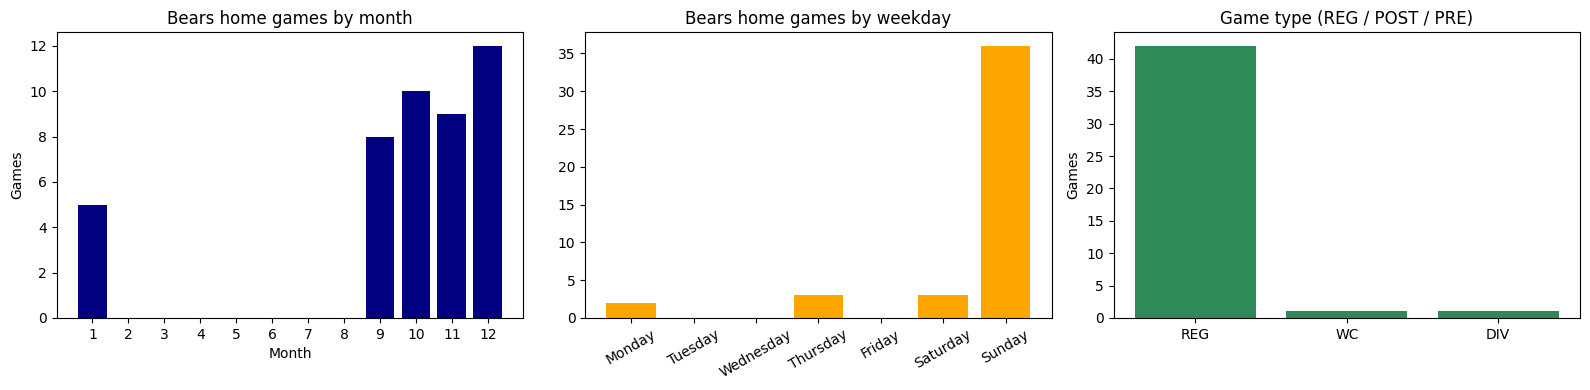

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

by_month = bears.assign(month=bears['date'].dt.month).groupby('month').size()
axes[0].bar(by_month.index, by_month.values, color='navy')
axes[0].set_title('Bears home games by month')
axes[0].set_xlabel('Month'); axes[0].set_ylabel('Games')
axes[0].set_xticks(range(1, 13))

by_dow = bears.assign(dow=bears['date'].dt.day_name()).groupby('dow').size().reindex(
    ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
)
axes[1].bar(by_dow.index, by_dow.values, color='orange')
axes[1].set_title('Bears home games by weekday')
axes[1].tick_params(axis='x', rotation=30)

by_type = bears['game_type'].value_counts()
axes[2].bar(by_type.index, by_type.values, color='seagreen')
axes[2].set_title('Game type (REG / POST / PRE)')
axes[2].set_ylabel('Games')

plt.tight_layout()
plt.show()

## 7. Signal check: rides near Soldier Field on game vs non-game days

In [24]:
soldier = venues.loc[venues['venue'] == 'Soldier Field'].iloc[0]
station_coords['dist_soldier_km'] = haversine_km(
    station_coords['start_lat'], station_coords['start_lng'],
    soldier['lat'], soldier['lng'],
)
near_soldier = station_coords[station_coords['dist_soldier_km'] <= 1.0]
print(f'Stations within 1 km of Soldier Field: {len(near_soldier)}')

near_set_b = set(near_soldier['start_station_name'])
bears_rides = (
    station[station['start_station_name'].isin(near_set_b)]
    .groupby('date')['total_rides'].sum().rename('rides_near_soldier').reset_index()
)
bears_rides['is_game_day'] = bears_rides['date'].isin(set(bears['date']))
bears_rides['month']       = bears_rides['date'].dt.month
bears_rides['dow']         = bears_rides['date'].dt.weekday

# Restrict to NFL season months (Sep–Jan); also restrict to Sundays only since that's when most Bears games are
in_season_b   = bears_rides[bears_rides['month'].isin([9, 10, 11, 12, 1])]
sundays_only  = in_season_b[in_season_b['dow'] == 6]

print('\n-- All in-season days (Sep–Jan) --')
print(in_season_b.groupby('is_game_day')['rides_near_soldier'].agg(['mean', 'median', 'count']))

print('\n-- Sundays only --')
sun_summary = sundays_only.groupby('is_game_day')['rides_near_soldier'].agg(['mean', 'median', 'count'])
print(sun_summary)

if True in sun_summary.index and False in sun_summary.index:
    lift = sun_summary.loc[True, 'mean'] / sun_summary.loc[False, 'mean'] - 1
    print(f'\nSunday game-day mean lift: {lift:.1%}')

Stations within 1 km of Soldier Field: 11

-- All in-season days (Sep–Jan) --
                   mean  median  count
is_game_day                           
False        302.869613   204.0    905
True         494.522727   440.0     44

-- Sundays only --
                   mean  median  count
is_game_day                           
False        317.595960   166.0     99
True         518.611111   495.0     36

Sunday game-day mean lift: 63.3%


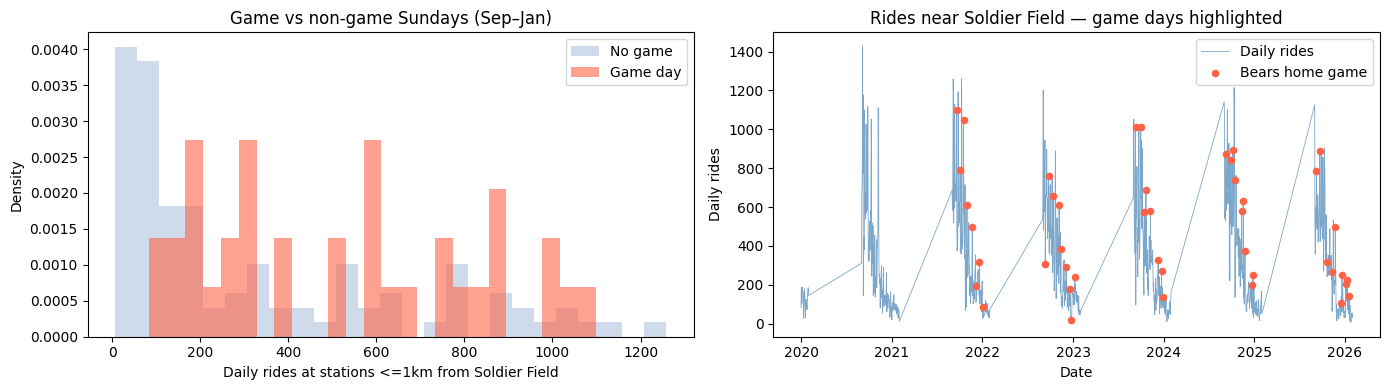

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

for is_game, color, label in [(False, 'lightsteelblue', 'No game'), (True, 'tomato', 'Game day')]:
    subset = sundays_only[sundays_only['is_game_day'] == is_game]['rides_near_soldier']
    if len(subset) > 0:
        axes[0].hist(subset, bins=25, alpha=0.6, color=color, label=label, density=True)
axes[0].set_xlabel('Daily rides at stations <=1km from Soldier Field')
axes[0].set_ylabel('Density')
axes[0].set_title('Game vs non-game Sundays (Sep–Jan)')
axes[0].legend()

# Time series — overlay game days as markers
season_window = bears_rides[bears_rides['month'].isin([9, 10, 11, 12, 1])].sort_values('date')
axes[1].plot(season_window['date'], season_window['rides_near_soldier'], color='steelblue', linewidth=0.6, alpha=0.7, label='Daily rides')
game_days = season_window[season_window['is_game_day']]
axes[1].scatter(game_days['date'], game_days['rides_near_soldier'], color='tomato', s=20, zorder=5, label='Bears home game')
axes[1].set_title('Rides near Soldier Field — game days highlighted')
axes[1].set_xlabel('Date'); axes[1].set_ylabel('Daily rides')
axes[1].legend()

plt.tight_layout()
plt.show()

## 8. Bulls home games at United Center

NBA: 41 regular-season home games + playoffs, Oct–Apr (Jun in deep playoff runs). United Center is shared with the Blackhawks — so the venue's true event-day signal will combine both.

Using `nba_api.stats.endpoints.leaguegamefinder` — install with `uv add nba-api`.

In [26]:
from nba_api.stats.endpoints import leaguegamefinder

BULLS_TEAM_ID = 1610612741   # Chicago Bulls

games = leaguegamefinder.LeagueGameFinder(
    team_id_nullable=BULLS_TEAM_ID,
    date_from_nullable='01/01/2021',
).get_data_frames()[0]

# Home games: 'MATCHUP' has 'vs.' for home, '@' for away
bulls = games[games['MATCHUP'].str.contains('vs\\.', regex=True)].copy()
bulls['date']   = pd.to_datetime(bulls['GAME_DATE'])
bulls['season'] = bulls['SEASON_ID'].str[-4:].astype(int)
bulls = bulls[['season', 'date', 'MATCHUP', 'WL', 'PTS']].rename(
    columns={'MATCHUP': 'matchup', 'WL': 'result', 'PTS': 'points'}
)
bulls['opponent'] = bulls['matchup'].str.split(' vs. ').str[1]
print(f'Bulls home games: {len(bulls):,}  ({bulls["date"].min().date()} → {bulls["date"].max().date()})')
bulls.head()

Bulls home games: 257  (2021-01-03 → 2026-04-10)


,season,date,matchup,result,points,opponent
1,2025,2026-04-10,CHI vs. ORL,L,103,ORL
4,2025,2026-04-05,CHI vs. PHX,L,110,PHX
6,2025,2026-04-01,CHI vs. IND,L,126,IND
11,2025,2026-03-23,CHI vs. HOU,W,132,HOU
12,2025,2026-03-19,CHI vs. CLE,L,110,CLE


In [27]:
bulls.groupby('season').size().to_frame('home_games')

,home_games
season,
2020,33
2021,46
2022,44
2023,45
2024,45
2025,44


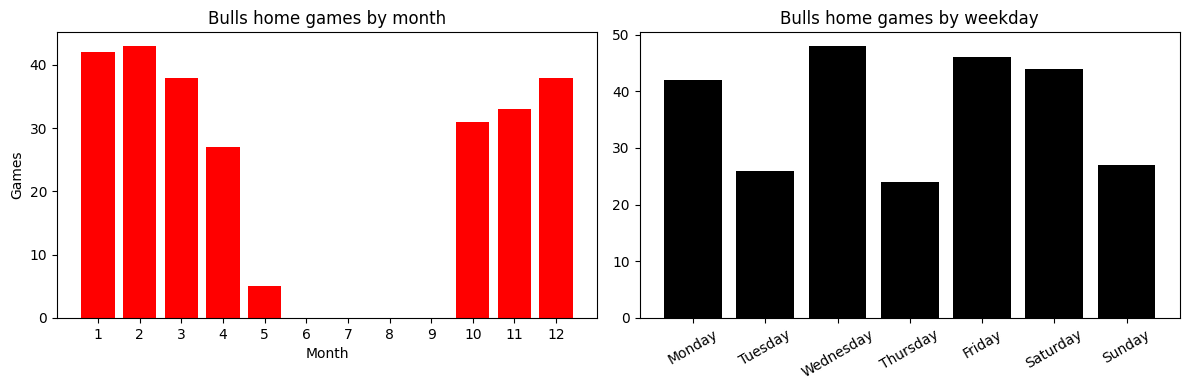

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

by_month = bulls.assign(month=bulls['date'].dt.month).groupby('month').size()
axes[0].bar(by_month.index, by_month.values, color='red')
axes[0].set_title('Bulls home games by month')
axes[0].set_xlabel('Month'); axes[0].set_ylabel('Games')
axes[0].set_xticks(range(1, 13))

by_dow = bulls.assign(dow=bulls['date'].dt.day_name()).groupby('dow').size().reindex(
    ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
)
axes[1].bar(by_dow.index, by_dow.values, color='black')
axes[1].set_title('Bulls home games by weekday')
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

## 9. Signal check: rides near United Center on Bulls game vs non-game days

Note: United Center also hosts Blackhawks games and concerts. "Non-game day" here might still be a Hawks/concert day — so the measured Bulls-only lift is an *under*estimate of total venue effect.

In [29]:
uc = venues.loc[venues['venue'] == 'United Center'].iloc[0]
station_coords['dist_uc_km'] = haversine_km(
    station_coords['start_lat'], station_coords['start_lng'],
    uc['lat'], uc['lng'],
)
near_uc = station_coords[station_coords['dist_uc_km'] <= 1.0]
print(f'Stations within 1 km of United Center: {len(near_uc)}')

near_set_uc = set(near_uc['start_station_name'])
bulls_rides = (
    station[station['start_station_name'].isin(near_set_uc)]
    .groupby('date')['total_rides'].sum().rename('rides_near_uc').reset_index()
)
bulls_rides['is_bulls_game'] = bulls_rides['date'].isin(set(bulls['date']))
bulls_rides['month']         = bulls_rides['date'].dt.month

in_season_uc = bulls_rides[bulls_rides['month'].isin([10, 11, 12, 1, 2, 3, 4, 5, 6])]
summary = in_season_uc.groupby('is_bulls_game')['rides_near_uc'].agg(['mean', 'median', 'count'])
print(summary)

if True in summary.index and False in summary.index:
    lift = summary.loc[True, 'mean'] / summary.loc[False, 'mean'] - 1
    print(f'\nBulls game-day mean lift: {lift:.1%}')

Stations within 1 km of United Center: 7
                    mean  median  count
is_bulls_game                          
False          54.598480    49.0   1447
True           56.427419    49.5    248

Bulls game-day mean lift: 3.3%


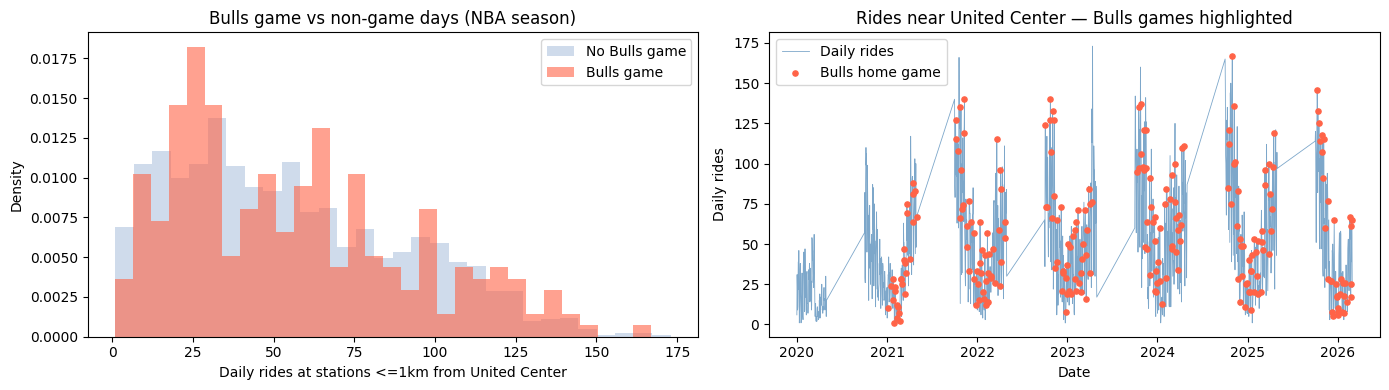

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

for is_game, color, label in [(False, 'lightsteelblue', 'No Bulls game'), (True, 'tomato', 'Bulls game')]:
    subset = in_season_uc[in_season_uc['is_bulls_game'] == is_game]['rides_near_uc']
    if len(subset) > 0:
        axes[0].hist(subset, bins=30, alpha=0.6, color=color, label=label, density=True)
axes[0].set_xlabel('Daily rides at stations <=1km from United Center')
axes[0].set_ylabel('Density')
axes[0].set_title('Bulls game vs non-game days (NBA season)')
axes[0].legend()

season_window = bulls_rides[bulls_rides['month'].isin([10, 11, 12, 1, 2, 3, 4])].sort_values('date')
axes[1].plot(season_window['date'], season_window['rides_near_uc'], color='steelblue', linewidth=0.6, alpha=0.7, label='Daily rides')
game_days = season_window[season_window['is_bulls_game']]
axes[1].scatter(game_days['date'], game_days['rides_near_uc'], color='tomato', s=14, zorder=5, label='Bulls home game')
axes[1].set_title('Rides near United Center — Bulls games highlighted')
axes[1].set_xlabel('Date'); axes[1].set_ylabel('Daily rides')
axes[1].legend()

plt.tight_layout()
plt.show()

## 10. Blackhawks home games at United Center

NHL: 41 home games per regular season + playoffs, Oct–Apr. Same venue as Bulls — combining the two should make the United Center signal much cleaner.

Using the NHL public API directly (no extra dependency).

In [31]:
import requests

HAWKS_SEASONS = ['20202021', '20212022', '20222023', '20232024', '20242025', '20252026']
frames = []
for s in HAWKS_SEASONS:
    r = requests.get(f'https://api-web.nhle.com/v1/club-schedule-season/CHI/{s}')
    games = r.json().get('games', [])
    for g in games:
        if g['homeTeam']['abbrev'] != 'CHI':
            continue
        frames.append({
            'season':   s,
            'date':     pd.to_datetime(g['gameDate']),
            'opponent': g['awayTeam']['abbrev'],
            'game_type': g.get('gameType'),
        })
hawks = pd.DataFrame(frames)
print(f'Blackhawks home games: {len(hawks):,}  ({hawks["date"].min().date()} → {hawks["date"].max().date()})')
hawks.head()

Blackhawks home games: 248  (2021-01-22 → 2026-04-15)


,season,date,opponent,game_type
0,20202021,2021-01-22,DET,2
1,20202021,2021-01-24,DET,2
2,20202021,2021-01-29,CBJ,2
3,20202021,2021-01-31,CBJ,2
4,20202021,2021-02-02,CAR,2


In [32]:
hawks.groupby(['season', 'game_type']).size().unstack(fill_value=0)

game_type,1,2
season,,
20202021,0,28
20212022,3,41
20222023,3,41
20232024,3,41
20242025,3,41
20252026,3,41


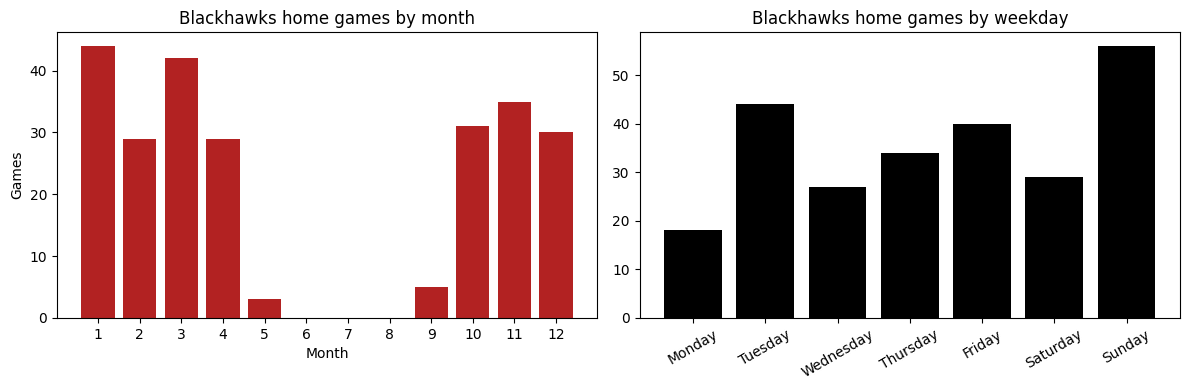

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

by_month = hawks.assign(month=hawks['date'].dt.month).groupby('month').size()
axes[0].bar(by_month.index, by_month.values, color='firebrick')
axes[0].set_title('Blackhawks home games by month')
axes[0].set_xlabel('Month'); axes[0].set_ylabel('Games')
axes[0].set_xticks(range(1, 13))

by_dow = hawks.assign(dow=hawks['date'].dt.day_name()).groupby('dow').size().reindex(
    ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
)
axes[1].bar(by_dow.index, by_dow.values, color='black')
axes[1].set_title('Blackhawks home games by weekday')
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

## 11. Combined United Center signal: Bulls **or** Blackhawks game

With both teams marked, the "any UC event" lift should be cleaner than Bulls-only.

In [34]:
all_uc_games = set(bulls['date']) | set(hawks['date'])

uc_rides = (
    station[station['start_station_name'].isin(near_set_uc)]
    .groupby('date')['total_rides'].sum().rename('rides_near_uc').reset_index()
)
uc_rides['is_uc_event'] = uc_rides['date'].isin(all_uc_games)
uc_rides['month']       = uc_rides['date'].dt.month

in_season_uc_all = uc_rides[uc_rides['month'].isin([10, 11, 12, 1, 2, 3, 4, 5, 6])]

summary = in_season_uc_all.groupby('is_uc_event')['rides_near_uc'].agg(['mean', 'median', 'count'])
print(summary)

if True in summary.index and False in summary.index:
    lift = summary.loc[True, 'mean'] / summary.loc[False, 'mean'] - 1
    print(f'\nUC event-day mean lift (Bulls + Hawks): {lift:.1%}')

                  mean  median  count
is_uc_event                          
False        55.103789    50.0   1214
True         54.266112    47.0    481

UC event-day mean lift (Bulls + Hawks): -1.5%


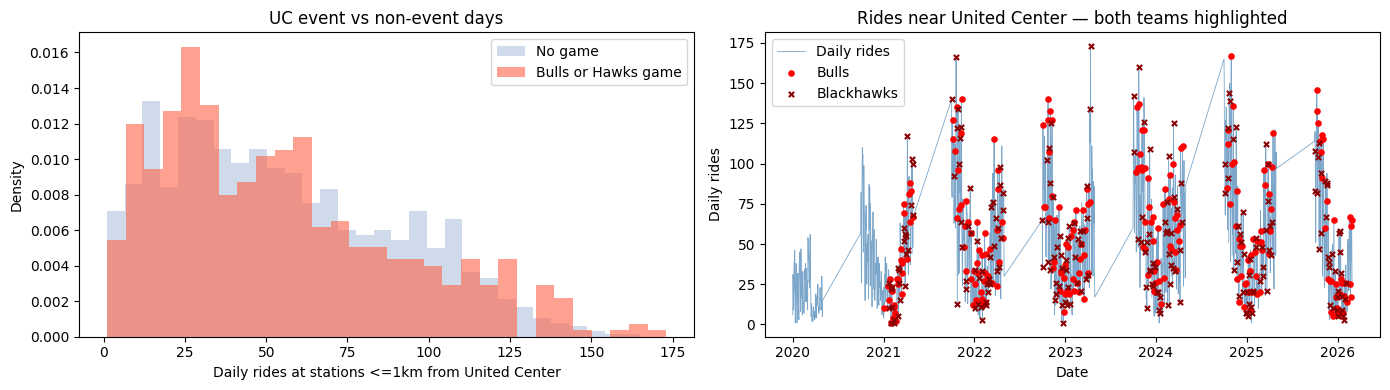

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

for is_event, color, label in [(False, 'lightsteelblue', 'No game'), (True, 'tomato', 'Bulls or Hawks game')]:
    subset = in_season_uc_all[in_season_uc_all['is_uc_event'] == is_event]['rides_near_uc']
    if len(subset) > 0:
        axes[0].hist(subset, bins=30, alpha=0.6, color=color, label=label, density=True)
axes[0].set_xlabel('Daily rides at stations <=1km from United Center')
axes[0].set_ylabel('Density')
axes[0].set_title('UC event vs non-event days')
axes[0].legend()

season_window = uc_rides[uc_rides['month'].isin([10, 11, 12, 1, 2, 3, 4])].sort_values('date')
axes[1].plot(season_window['date'], season_window['rides_near_uc'], color='steelblue', linewidth=0.6, alpha=0.7, label='Daily rides')
bulls_days = season_window[season_window['date'].isin(set(bulls['date']))]
hawks_days = season_window[season_window['date'].isin(set(hawks['date']))]
axes[1].scatter(bulls_days['date'], bulls_days['rides_near_uc'], color='red',     s=14, zorder=5, label='Bulls')
axes[1].scatter(hawks_days['date'], hawks_days['rides_near_uc'], color='darkred', s=14, marker='x', zorder=5, label='Blackhawks')
axes[1].set_title('Rides near United Center — both teams highlighted')
axes[1].set_xlabel('Date'); axes[1].set_ylabel('Daily rides')
axes[1].legend()

plt.tight_layout()
plt.show()

## 12. White Sox home games at Guaranteed Rate Field

MLB: 81 home games/year, Apr–Sep, similar to Cubs. South side though — Divvy density is lower around the venue.

In [41]:
frames = []
for yr in SEASONS:
    sched = schedule_and_record(yr, 'CHW')
    sched = sched[sched['Home_Away'] == 'Home'].copy()
    sched['season'] = yr
    frames.append(sched)
sox = pd.concat(frames, ignore_index=True)

sox['date'] = pd.to_datetime(
    sox['Date'].str.replace(r' \(\d+\)', '', regex=True) + ' ' + sox['season'].astype(str),
    format='%A, %b %d %Y',
    errors='coerce',
)
sox = sox.dropna(subset=['date'])
sox = sox[['season', 'date', 'Opp', 'D/N', 'W/L', 'Attendance']].rename(
    columns={'Opp': 'opponent', 'D/N': 'day_night', 'W/L': 'result', 'Attendance': 'attendance'}
)
print(f'White Sox home games: {len(sox):,}  ({sox["date"].min().date()} → {sox["date"].max().date()})')
sox.head()

http://www.baseball-reference.com/teams/CHW/2021-schedule-scores.shtml
http://www.baseball-reference.com/teams/CHW/2022-schedule-scores.shtml


/Users/zimenghuang/Desktop/codes/hobby_projects/Divvy/divvy/.venv/lib/python3.11/site-packages/pybaseball/team_results.py:75: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df['Attendance'].replace(r'^Unknown$', np.nan, regex=True, inplace = True) # make this a NaN so the column can benumeric
/Users/zimenghuang/Desktop/codes/hobby_pro

http://www.baseball-reference.com/teams/CHW/2023-schedule-scores.shtml


/Users/zimenghuang/Desktop/codes/hobby_projects/Divvy/divvy/.venv/lib/python3.11/site-packages/pybaseball/team_results.py:75: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df['Attendance'].replace(r'^Unknown$', np.nan, regex=True, inplace = True) # make this a NaN so the column can benumeric


http://www.baseball-reference.com/teams/CHW/2024-schedule-scores.shtml


/Users/zimenghuang/Desktop/codes/hobby_projects/Divvy/divvy/.venv/lib/python3.11/site-packages/pybaseball/team_results.py:75: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df['Attendance'].replace(r'^Unknown$', np.nan, regex=True, inplace = True) # make this a NaN so the column can benumeric


http://www.baseball-reference.com/teams/CHW/2025-schedule-scores.shtml
White Sox home games: 402  (2021-04-08 → 2025-09-21)


/Users/zimenghuang/Desktop/codes/hobby_projects/Divvy/divvy/.venv/lib/python3.11/site-packages/pybaseball/team_results.py:75: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df['Attendance'].replace(r'^Unknown$', np.nan, regex=True, inplace = True) # make this a NaN so the column can benumeric


,season,date,opponent,day_night,result,attendance
0,2021,2021-04-08,KCR,D,W,NaN
1,2021,2021-04-11,KCR,D,L,NaN
2,2021,2021-04-12,CLE,N,W-wo,NaN
3,2021,2021-04-13,CLE,N,L,NaN
4,2021,2021-04-14,CLE,N,W,NaN


In [42]:
sox.groupby('season').size().to_frame('home_games')

,home_games
season,
2021,80
2022,80
2023,80
2024,81
2025,81


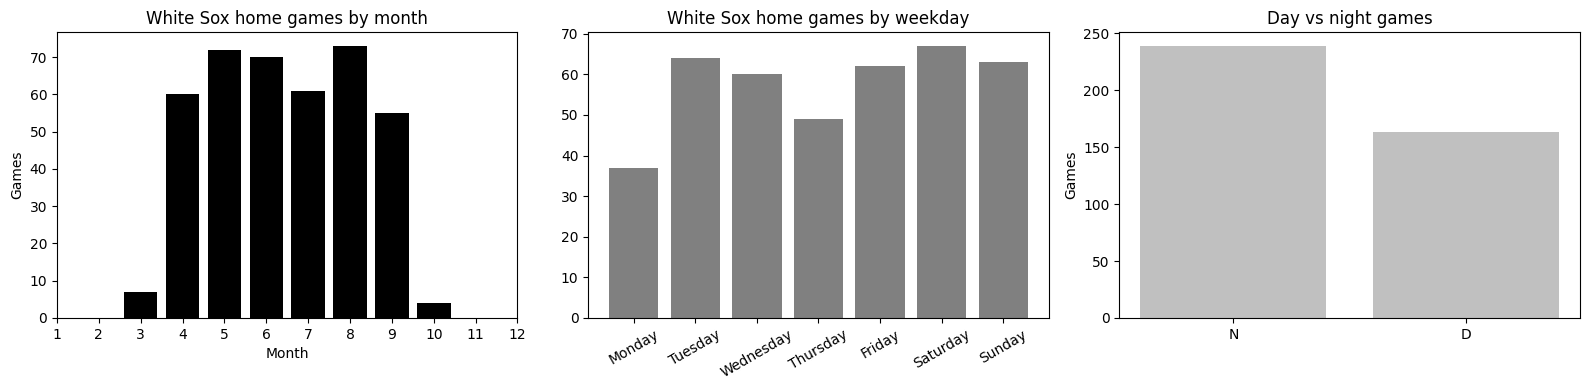

In [43]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

by_month = sox.assign(month=sox['date'].dt.month).groupby('month').size()
axes[0].bar(by_month.index, by_month.values, color='black')
axes[0].set_title('White Sox home games by month')
axes[0].set_xlabel('Month'); axes[0].set_ylabel('Games')
axes[0].set_xticks(range(1, 13))

by_dow = sox.assign(dow=sox['date'].dt.day_name()).groupby('dow').size().reindex(
    ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
)
axes[1].bar(by_dow.index, by_dow.values, color='gray')
axes[1].set_title('White Sox home games by weekday')
axes[1].tick_params(axis='x', rotation=30)

by_dn = sox['day_night'].value_counts()
axes[2].bar(by_dn.index, by_dn.values, color='silver')
axes[2].set_title('Day vs night games')
axes[2].set_ylabel('Games')

plt.tight_layout()
plt.show()

## 13. Signal check: rides near Guaranteed Rate Field

In [44]:
grf = venues.loc[venues['venue'] == 'Guaranteed Rate Field'].iloc[0]
station_coords['dist_grf_km'] = haversine_km(
    station_coords['start_lat'], station_coords['start_lng'],
    grf['lat'], grf['lng'],
)
near_grf = station_coords[station_coords['dist_grf_km'] <= 1.0]
print(f'Stations within 1 km of Guaranteed Rate Field: {len(near_grf)}')

near_set_grf = set(near_grf['start_station_name'])
sox_rides = (
    station[station['start_station_name'].isin(near_set_grf)]
    .groupby('date')['total_rides'].sum().rename('rides_near_grf').reset_index()
)
sox_rides['is_game_day'] = sox_rides['date'].isin(set(sox['date']))
sox_rides['month']       = sox_rides['date'].dt.month

in_season_sox = sox_rides[sox_rides['month'].between(4, 9)]
summary = in_season_sox.groupby('is_game_day')['rides_near_grf'].agg(['mean', 'median', 'count'])
print(summary)

if True in summary.index and False in summary.index:
    lift = summary.loc[True, 'mean'] / summary.loc[False, 'mean'] - 1
    print(f'\nWhite Sox game-day mean lift: {lift:.1%}')

Stations within 1 km of Guaranteed Rate Field: 8
                   mean  median  count
is_game_day                           
False         81.966527    74.0    717
True         114.894180   110.0    378

White Sox game-day mean lift: 40.2%


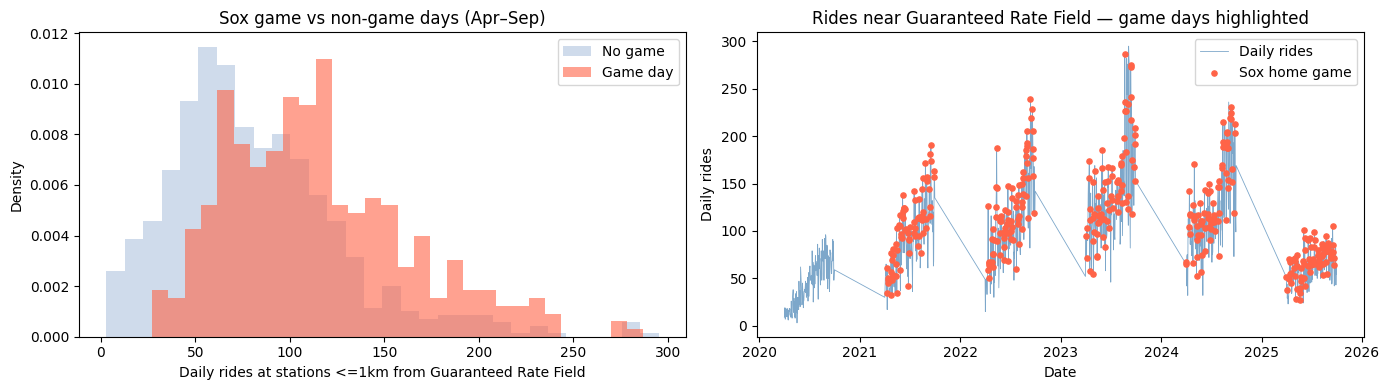

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

for is_game, color, label in [(False, 'lightsteelblue', 'No game'), (True, 'tomato', 'Game day')]:
    subset = in_season_sox[in_season_sox['is_game_day'] == is_game]['rides_near_grf']
    if len(subset) > 0:
        axes[0].hist(subset, bins=30, alpha=0.6, color=color, label=label, density=True)
axes[0].set_xlabel('Daily rides at stations <=1km from Guaranteed Rate Field')
axes[0].set_ylabel('Density')
axes[0].set_title('Sox game vs non-game days (Apr–Sep)')
axes[0].legend()

season_window = sox_rides[sox_rides['month'].between(4, 9)].sort_values('date')
axes[1].plot(season_window['date'], season_window['rides_near_grf'], color='steelblue', linewidth=0.6, alpha=0.7, label='Daily rides')
game_days = season_window[season_window['is_game_day']]
axes[1].scatter(game_days['date'], game_days['rides_near_grf'], color='tomato', s=14, zorder=5, label='Sox home game')
axes[1].set_title('Rides near Guaranteed Rate Field — game days highlighted')
axes[1].set_xlabel('Date'); axes[1].set_ylabel('Daily rides')
axes[1].legend()

plt.tight_layout()
plt.show()

## 14. Next steps

- Pull concert/festival schedules (Ticketmaster, Chicago Open Data Portal special-event permits) — currently sports-only
- Build `events.parquet` with `(date, venue, lat, lng, event_type, attendance_est)`
- Wire event features (`event_within_1km_today`, distance-weighted attendance) into the LSTM/XGBoost feature set